# A conventional treatment train (`difflow_water.treatment`)

Sedimentation, rapid filtration, granular activated carbon and chlorine disinfection, in series, on 1 m3/s of surface water carrying two floc classes, a dissolved organic micropollutant and *Giardia* cysts. Each unit is a palette operation; here they are chained in Python and differentiated end to end.

What the units are, and how far to trust them (see the docs page for the references and their status):

- **Sedimentation**: the ideal basin (Hazen 1904, Camp 1946): removal `min(1, v_s / (Q/A))`, Stokes settling.
- **Filtration**: clean-bed colloid filtration (Yao et al. 1971, single collector efficiency as restated by Messina et al. 2015) and Carman-Kozeny head loss.
- **GAC**: WaterTAP's constant-pattern HSDM; matches WaterTAP 1.8.0 to 2e-14.
- **Disinfection**: Chick-Watson kinetics in CSTRs in series.

All particle sizes, densities, rate constants and isotherm values below are ILLUSTRATIVE.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from difflow import make_stream

import difflow_water as dw
from difflow_water.treatment import collector_efficiency

# 1 m3/s of water; 20 g/s fine floc (10 um) and 30 g/s coarse floc (50 um); 4.4 g/s
# micropollutant (MW 80 g/mol, 4.4 mg/L); 1000 cysts/s
feed = make_stream({"H2O": 5.55e4, "TSS_fine": 20.0, "TSS_coarse": 30.0,
                    "solute": 0.0548, "Giardia": 1e3}, T=288.15, P=101325.0)

def train(x, feed=feed):
    A_sed, A_filt, ebct, dose, V_contact = x
    clear, sludge, s = dw.Sedimentation(dw.SedimentationParams(area=A_sed))(feed)
    filt, kept, f = dw.Filtration(dw.FiltrationParams(area=A_filt))(clear)
    treated, removed, g = dw.GACAdsorber(dw.GACParams(ebct=ebct, velocity_sup=6.0 / ebct))(filt)
    out, d = dw.Disinfection(dw.DisinfectionParams(dose=dose, volume=V_contact))(treated)
    tss_in = feed["F_TSS_fine"] + feed["F_TSS_coarse"]
    tss_out = out["F_TSS_fine"] + out["F_TSS_coarse"]
    return {"out": out, "sed": s, "filt": f, "gac": g, "dis": d,
            "tss_removal": 1.0 - tss_out / tss_in,
            "solute_removal": 1.0 - out["F_solute"] / feed["F_solute"]}

x0 = jnp.array([2000.0, 300.0, 600.0, 1.5, 500.0])
r = train(x0)
print(f"settling: overflow {float(r['sed']['overflow_rate'])*3600:.2f} m/h, removal per class {np.round(np.asarray(r['sed']['removal']), 3)}")
print(f"filter:   rate {float(r['filt']['filtration_rate'])*3600:.1f} m/h, eta {np.asarray(r['filt']['eta'])}, head loss {float(r['filt']['head_loss']):.2f} m")
print(f"GAC:      bed life {float(r['gac']['operational_time'])/86400:.0f} d, carbon {float(r['gac']['gac_usage_rate'])*86400:.0f} kg/d, removal {float(r['gac']['removal_fraction']):.3f}")
print(f"chlorine: CT {float(r['dis']['CT']):.1f} mg min/L, {float(r['dis']['log_inactivation']):.2f} log, residual {float(r['dis']['residual']):.2f} mg/L")
print(f"train:    TSS removal {float(r['tss_removal']):.4f}, micropollutant removal {float(r['solute_removal']):.3f}")

settling: overflow 1.80 m/h, removal per class [0.005 0.479]
filter:   rate 12.0 m/h, eta [0.00135086 0.08689864], head loss 1.31 m
GAC:      bed life 53 d, carbon 5098 kg/d, removal 0.947
chlorine: CT 11.9 mg min/L, 0.85 log, residual 1.38 mg/L
train:    TSS removal 0.8351, micropollutant removal 0.947


## Which particles get through

The filter's single collector efficiency has a minimum at about 1 um, where particles are too large to diffuse and too small to settle or be intercepted: the classic filtration window. Yao's three terms, at the design's filtration rate:

least-removed particle: 1.63 um, eta = 1.42e-04


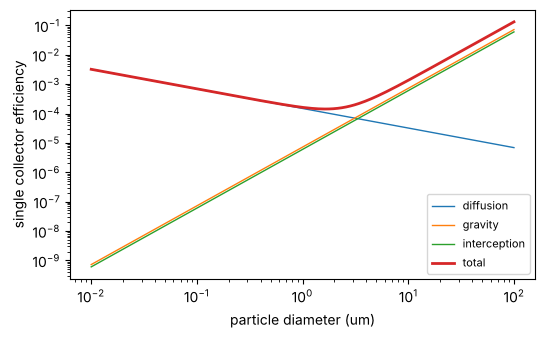

In [2]:
dps = jnp.logspace(-8, -4, 200)
U = r["filt"]["filtration_rate"]
ce = collector_efficiency(dps, 1050.0, 0.5e-3, U, 288.15)
fig, ax = plt.subplots(figsize=(6, 3.5))
for k, lab in [("eta_D", "diffusion"), ("eta_G", "gravity"), ("eta_I", "interception"), ("eta", "total")]:
    ax.loglog(dps * 1e6, ce[k], label=lab, lw=2 if k == "eta" else 1)
ax.set_xlabel("particle diameter (um)"); ax.set_ylabel("single collector efficiency"); ax.legend(fontsize=8)
i = int(jnp.argmin(ce["eta"])); print(f"least-removed particle: {float(dps[i])*1e6:.2f} um, eta = {float(ce['eta'][i]):.2e}")

## Sensitivities of the train, with `jax.jacfwd`

How the train's performance moves with each design variable: settling area, filter area, GAC empty-bed contact time, chlorine dose and contact-tank volume. One forward-mode Jacobian gives all of them.

In [3]:
def metrics(x):
    t = train(x)
    return jnp.stack([t["tss_removal"], t["solute_removal"], t["dis"]["log_inactivation"],
                      t["filt"]["head_loss"], t["gac"]["gac_usage_rate"] * 86400])
J = jax.jacfwd(metrics)(x0)
rows = ["TSS removal", "micropollutant removal", "Giardia log inactivation", "filter head loss (m)", "carbon use (kg/d)"]
cols = ["A_sed (m2)", "A_filter (m2)", "EBCT (s)", "Cl2 (mg/L)", "V_contact (m3)"]
print(f"{'d metric / d design':28s}" + "".join(f"{c:>17s}" for c in cols))
for name, row in zip(rows, np.asarray(J)):
    print(f"{name:28s}" + "".join(f"{v:17.3e}" for v in row))

d metric / d design                A_sed (m2)    A_filter (m2)         EBCT (s)       Cl2 (mg/L)   V_contact (m3)
TSS removal                         4.255e-07        2.654e-04        0.000e+00        0.000e+00        0.000e+00
micropollutant removal             -1.268e-09       -0.000e+00        8.159e-05       -0.000e+00       -0.000e+00
Giardia log inactivation            2.363e-07        0.000e+00        0.000e+00        4.670e-01        1.333e-03
filter head loss (m)               -4.745e-07       -4.371e-03       -0.000e+00       -0.000e+00       -0.000e+00
carbon use (kg/d)                  -1.625e-03        0.000e+00       -1.387e-01        0.000e+00        0.000e+00


## A small design problem

Cheapest GAC contact time, chlorine dose and contact-tank volume that give 3 log *Giardia* inactivation and 90 % micropollutant removal, with ILLUSTRATIVE prices (carbon 1.5 USD/kg, chlorine 2 USD/kg, contact tank and GAC bed 0.3 USD per m3 of volume per day; without a price on the bed, a longer bed only saves carbon and the contact time runs to its bound). Settling and filtration do not touch dissolved solutes or cysts in this model (no filtration credit for cysts, a deliberate simplification), so their areas stay fixed. The design at the start (8 min of contact) gives less than 1 log. SLSQP with `jax` gradients:

In [4]:
from scipy.optimize import minimize
def cost(z):            # USD/day, ILLUSTRATIVE prices
    t = train(jnp.array([2000.0, 300.0, z[0], z[1], z[2]]))
    return (t["gac"]["gac_usage_rate"] * 86400 * 1.5 + z[1] * 86.4 * 2.0
            + 0.3 * (z[2] + t["gac"]["bed_volume"]))
def cons(z):
    t = train(jnp.array([2000.0, 300.0, z[0], z[1], z[2]]))
    return jnp.stack([t["dis"]["log_inactivation"] - 3.0, t["solute_removal"] - 0.9])
f, g = jax.jit(cost), jax.jit(jax.grad(cost))
c, cj = jax.jit(cons), jax.jit(jax.jacfwd(cons))
res = minimize(lambda z: float(f(z)), np.array([600.0, 1.5, 500.0]), jac=lambda z: np.asarray(g(z)),
               method="SLSQP", bounds=[(300.0, 3600.0), (0.2, 4.0), (100.0, 10000.0)],
               constraints=[{"type": "ineq", "fun": lambda z: np.asarray(c(z)), "jac": lambda z: np.asarray(cj(z))}])
print(res.message)
print(f"EBCT {res.x[0]:.0f} s, chlorine dose {res.x[1]:.2f} mg/L, contact tank {res.x[2]:.0f} m3; "
      f"cost {res.fun:.0f} USD/d; constraint margins {np.round(np.asarray(c(res.x)), 6)}")

Optimization terminated successfully
EBCT 501 s, chlorine dose 3.27 mg/L, contact tank 1598 m3; cost 8865 USD/d; constraint margins [-0.        0.037178]


## Limits

- Clean-bed filtration (no ripening, clogging or breakthrough), discrete settling only (no flocculation), no coagulation step.
- The GAC regression constants are WaterTAP's example values whatever Bi and 1/n are; in practice they come from Hand et al.'s tables for the actual Bi and 1/n.
- Chick-Watson constants are ILLUSTRATIVE; real CT requirements come from regulatory tables and depend on pH and temperature.